In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All libraries imported successfully!")

All libraries imported successfully!


In [27]:
df = pd.read_csv(r"E:\OIBSIP\DataAnalytics-L1-EDARetailSales\dataset\retail_sales_dataset.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [28]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [29]:
print("Data Shape", df.shape)
print("\n Dataset information")
df.info()

Data Shape (1000, 9)

 Dataset information
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [30]:
print("Missing Values:")
print(df.isnull().sum())

print("\n Duplicate Rows", df.duplicated().sum())

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

 Duplicate Rows 0


In [31]:
df["Date"] = pd.to_datetime(df["Date"])
print("date column data type: ",df["Date"].dtype)
df["Date"].head()

date column data type:  datetime64[us]


0   2023-11-24
1   2023-02-27
2   2023-01-13
3   2023-05-21
4   2023-05-06
Name: Date, dtype: datetime64[us]

In [32]:
numeric_df = df.select_dtypes(include=np.number)

print("MEAN")
display(numeric_df.mean())

print("MEDIAN")
display(numeric_df.median())

print("MODE")
display(numeric_df.mode())

print("STANDARD DEVIATION")
display(numeric_df.std())

MEAN


Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

MEDIAN


Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

MODE


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
0,1,43.0,4.0,50.0,50.0
1,2,64.0,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN
3,4,NaN,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN
...,...,...,...,...,...
995,996,NaN,NaN,NaN,NaN
996,997,NaN,NaN,NaN,NaN
997,998,NaN,NaN,NaN,NaN
998,999,NaN,NaN,NaN,NaN


STANDARD DEVIATION


Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

In [33]:
monthly_sales = df.groupby(df["Date"].dt.to_period('M'))['Total Amount'].sum()
display(monthly_sales)

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

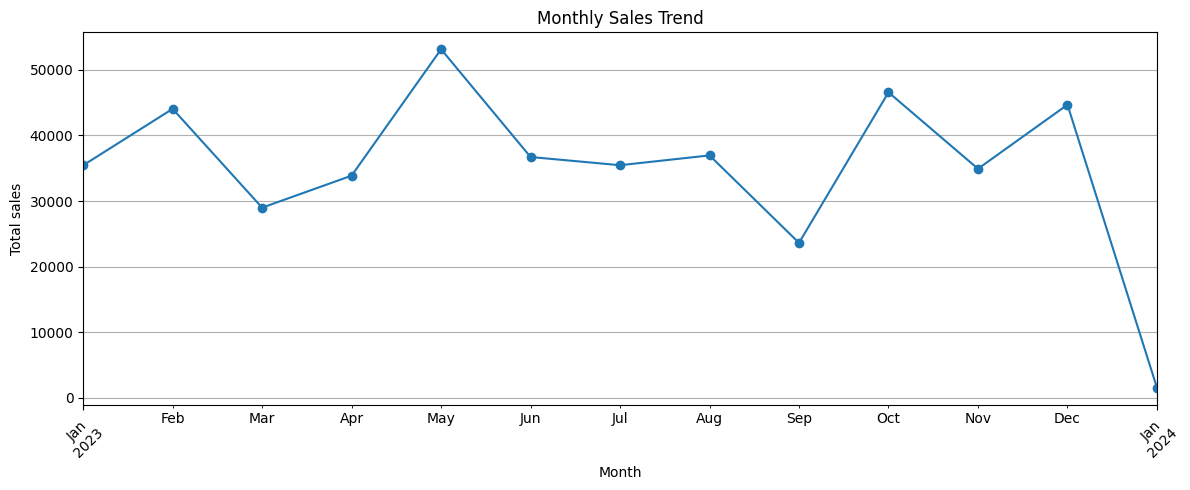

In [34]:
plt.figure(figsize=(12,5))
monthly_sales.plot(kind='line',marker = 'o')

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total sales")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [35]:
quarterly_sales = df.groupby(df["Date"].dt.to_period('Q'))['Total Amount'].sum()
display(quarterly_sales)

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

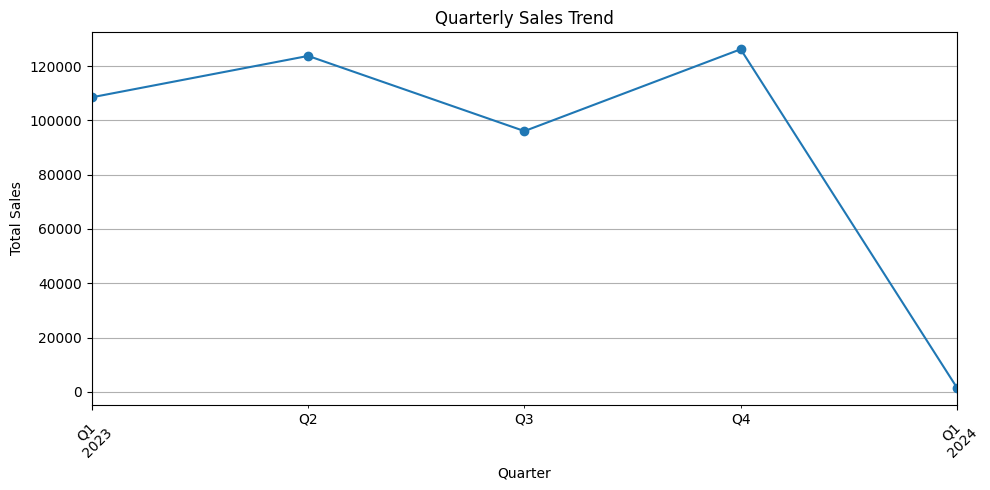

In [36]:
plt.figure(figsize=(10,5))

quarterly_sales.plot(kind='line', marker= 'o')

plt.title("Quarterly Sales Trend")
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation= 45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [37]:
df = pd.read_csv('dataset/retail_sales_dataset.csv')

display(df.head())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [38]:
import pandas as pd

print(pd.__version__)

3.0.1


In [39]:
print(df.shape)
print(df.columns)

(1000, 9)
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')


In [40]:
bins = [0, 25, 35, 45, 55, 100]

labels = ['18-25', '26-35', '36-45', '46-55', '56+']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels
)

age_distribution = df['Age Group'].value_counts().sort_index()

display(age_distribution)

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56+      195
Name: count, dtype: int64

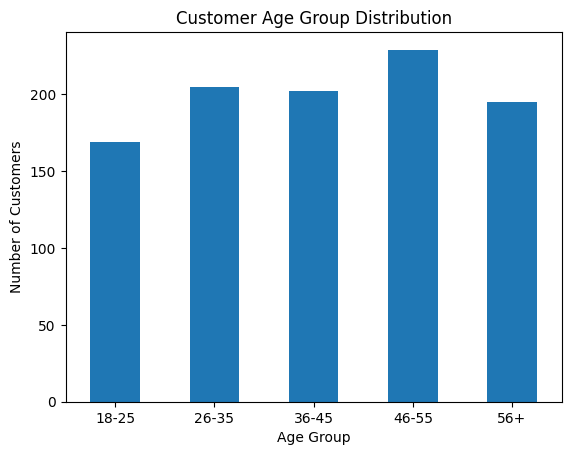

In [41]:
plt.Figure(figsize=(8,5))
age_distribution.plot(kind='bar')
plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)

plt.show()

### Observations:
- The 46-55 age group has the highest customer count (229).
- The 18-25 age group has the lowest customer count (169).
- Customer distribution is relatively balanced across all age groups.
- The business attracts customers from a wide range of age groups.

In [42]:
gender_distribution = df["Gender"].value_counts()
display(gender_distribution)

Gender
Female    510
Male      490
Name: count, dtype: int64

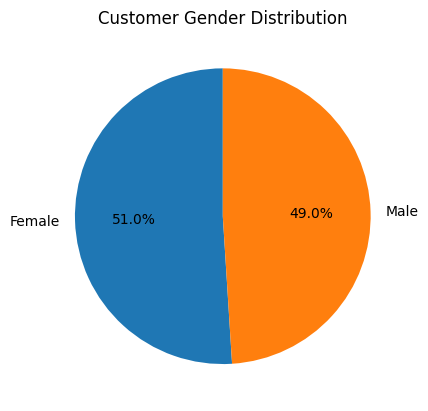

In [43]:
plt.Figure(figsize=(6,6))
gender_distribution.plot(kind="pie",autopct="%1.1f%%",startangle=90)
plt.title('Customer Gender Distribution')
plt.ylabel('')

plt.show()

### Observations:

- Female customers account for 51% of total customers (510).
- Male customers account for 49% of total customers (490).
- The gender distribution is almost equal.
- The business attracts customers from both genders at a similar rate.

In [44]:
category_sales = df.groupby('Product Category')['Total Amount'].sum()

display(category_sales)

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

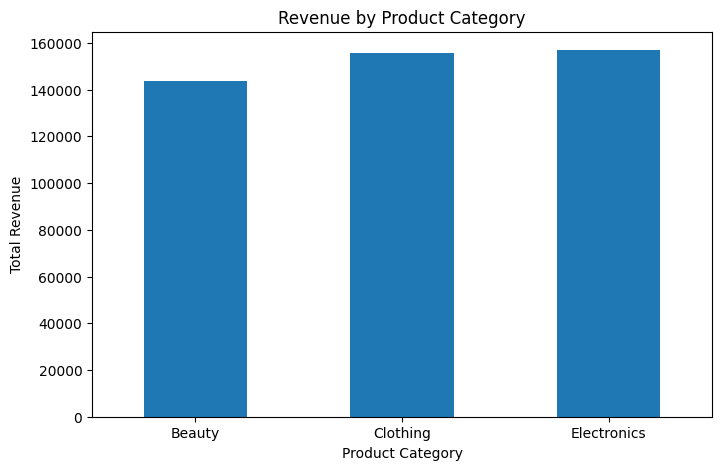

In [45]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)

plt.show()

### Observations:

- Electronics generates the highest revenue (156,905).
- Clothing generates the second-highest revenue (155,580).
- Beauty generates the lowest revenue (143,515).
- Revenue is relatively evenly distributed across all three product categories.

In [46]:
correlation_matrix = df.select_dtypes(include="number").corr()
display(correlation_matrix)

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
Transaction ID,1.000000,0.065191,-0.026623,-0.060837,-0.075034
Age,0.065191,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.026623,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.060837,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.075034,-0.060568,0.373707,0.851925,1.000000


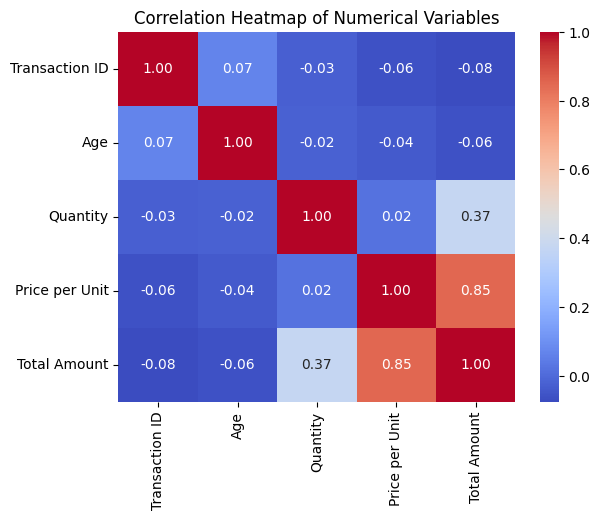

In [47]:
plt.Figure(figsize=(10,6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt='.2f'
)
plt.title('Correlation Heatmap of Numerical Variables')

plt.show()

In [48]:
display(correlation_matrix.round(2))

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
Transaction ID,1.00,0.07,-0.03,-0.06,-0.08
Age,0.07,1.00,-0.02,-0.04,-0.06
Quantity,-0.03,-0.02,1.00,0.02,0.37
Price per Unit,-0.06,-0.04,0.02,1.00,0.85
Total Amount,-0.08,-0.06,0.37,0.85,1.00


### Observations:

- Price per Unit and Total Amount show a strong positive correlation (0.85).
- Quantity and Total Amount show a moderate positive correlation (0.37).
- Customer Age has a very weak negative correlation with Total Amount (-0.06).
- Transaction ID has no meaningful relationship with sales performance.
- Overall, product price has a stronger linear relationship with transaction amount than quantity does.

In [49]:
age_spending = df.groupby('Age Group', observed=True)['Total Amount'].mean()
display(age_spending.round(2))

Age Group
18-25    500.30
26-35    480.39
36-45    454.80
46-55    439.69
56+      412.36
Name: Total Amount, dtype: float64

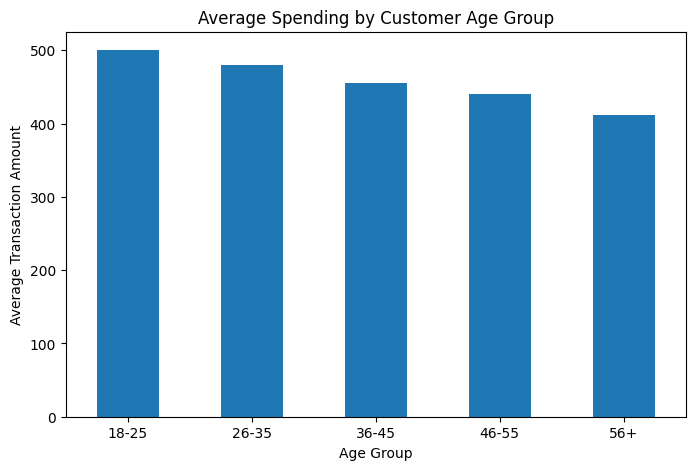

In [50]:
plt.figure(figsize=(8, 5))

age_spending.plot(kind='bar')

plt.title('Average Spending by Customer Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Amount')
plt.xticks(rotation=0)

plt.show()

### Observations:
- The 18-25 age group has the highest average spending (500.30).
- The 56+ age group has the lowest average spending (412.36).
- Average transaction spending gradually decreases as customer age increases.
- Younger customers show higher average transaction spending in this dataset.

## Conclusion

The exploratory data analysis of the retail sales dataset provided useful insights into sales performance, customer demographics, and purchasing behaviour.

The dataset contains 1,000 transactions, with no missing values or duplicate records. The analysis showed that Electronics generated the highest revenue among the three product categories, followed closely by Clothing.

Monthly and quarterly sales analysis revealed fluctuations in revenue throughout the year, with the fourth quarter of 2023 recording the highest quarterly sales. Customer demographic analysis showed a nearly equal distribution between male and female customers. The 46–55 age group had the highest number of customers, while the 18–25 age group recorded the highest average transaction amount.

The correlation analysis indicated a strong positive relationship between product price and total transaction amount. Overall, these findings can help a retail business understand its sales patterns, customer behaviour, and opportunities for improvement.

## Business Recommendations

Based on the analysis, the following recommendations can help improve retail business performance:

1. **Focus on high-revenue product categories:** Electronics generated the highest revenue (156,905). The business should maintain sufficient stock of popular electronic products and consider promotional campaigns to increase sales further.

2. **Develop targeted marketing strategies:** Customers aged 18–25 recorded the highest average transaction amount (500.30). The business can introduce targeted offers, discounts, and promotional campaigns to attract and retain younger customers.

3. **Improve quarterly sales performance:** The fourth quarter of 2023 recorded the highest sales (126,190), while the third quarter recorded lower sales (96,045). The business should analyse seasonal purchasing patterns and introduce special promotions during weaker sales periods.

4. **Maintain a balanced customer approach:** Female customers represented 51% of transactions and male customers 49%. Marketing campaigns should continue targeting both groups rather than focusing heavily on one gender.

5. **Use pricing strategies carefully:** Since Price per Unit has a strong positive correlation (0.85) with Total Amount, the business should review product pricing, product mix, and promotional discounts to improve transaction revenue.